# 0a_05 Probability Trees, Total Probability and a First Look at Bayes

**Learning objectives**
- Draw and read a **probability tree**: multiply along branches, add across branches.
- Use the **law of total probability** $P(B)=\sum_iP(B\mid A_i)P(A_i)$.
- Reverse a conditional probability with **Bayes' theorem** and with **natural frequencies** ("out of 1,000 emails ...").
- Understand why a good detector can still be wrong most of the time when the thing it detects is **rare** (the base-rate effect).

**Prerequisites:** [0a_04 Conditional probability and independence](0a_04_conditional_independence.ipynb). Module 00 lesson [00_05 Bayes' theorem](../../module_00_foundations/notebooks/00_05_bayes_theorem.ipynb) continues with the full theory.

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, itertools
from matplotlib.patches import FancyBboxPatch

## 2. Prerequisite recap

- $P(A\mid B)=\dfrac{P(A\cap B)}{P(B)}$ and $P(A\cap B)=P(B)\,P(A\mid B)$ (0a_04).
- Events $A_1,\dots,A_k$ form a **partition** if they are mutually exclusive and together cover everything (exactly one of them happens): for example {spam, not spam}, or machine A, B or C.
- Probabilities of mutually exclusive events add (0a_01).

## 3. Intuition and story

Many real situations have two stages: first something happens (an email is spam or not; a part comes from machine A, B or C; a customer is fraudulent or not), then a second thing is observed (the filter flags it; the part is defective; the alert rings). We usually know the **forward** probabilities ("a spam email is flagged 95 % of the time") but want the **backward** one ("this email was flagged; how likely is it spam?").

Two tools solve it:

1. A **probability tree** lists every path: multiply the probabilities along a path to get the probability of that scenario, and add the paths that lead to the same observation.
2. **Natural frequencies**: imagine 1,000 emails and count how many fall on each path. Counts are easier to reason about than percentages.

Bayes' theorem is just the tree read backwards: of all paths ending in "flagged", what fraction started with "spam"?

## 4. Formal definitions

**Partition.** $A_1,\dots,A_k$ are mutually exclusive and exhaustive: $P(A_1)+\cdots+P(A_k)=1$.

**Law of total probability.** For any event $B$,
$$P(B)=\sum_{i=1}^kP(B\cap A_i)=\sum_{i=1}^kP(B\mid A_i)\,P(A_i).$$

**Bayes' theorem.** For $P(B)>0$,
$$P(A_j\mid B)=\frac{P(B\mid A_j)\,P(A_j)}{\sum_iP(B\mid A_i)\,P(A_i)}.$$
The terms have names: $P(A_j)$ is the **prior** (before seeing $B$), $P(B\mid A_j)$ the **likelihood**, $P(A_j\mid B)$ the **posterior** (after seeing $B$).

**Binary detector vocabulary** (the event $D$ = "has the condition", $+$ = "test is positive"):

| Name | Meaning | Formula |
|---|---|---|
| prevalence / base rate | how common the condition is | $P(D)$ |
| **sensitivity** (recall, true positive rate) | catches a true case | $P(+\mid D)$ |
| **specificity** (true negative rate) | clears a non-case | $P(-\mid D^c)$ |
| **false positive rate** | wrongly alarms | $P(+\mid D^c)=1-\text{specificity}$ |
| **precision** (positive predictive value) | alarm is right | $P(D\mid+)$ |

## 5. Derivations

### 5.1 Total probability
Because $A_1,\dots,A_k$ partition the sample space, the event $B$ splits into the disjoint pieces $B\cap A_1,\dots,B\cap A_k$, so $P(B)=\sum P(B\cap A_i)$ by the addition rule; and $P(B\cap A_i)=P(B\mid A_i)P(A_i)$ by the multiplication rule. **In plain words.** To find the chance of something, split the world into cases, find the chance within each case, and weight by how likely each case is.

### 5.2 Bayes' theorem
By the multiplication rule written two ways, $P(A_j\mid B)P(B)=P(A_j\cap B)=P(B\mid A_j)P(A_j)$. Dividing by $P(B)$ and using total probability for $P(B)$ gives Bayes' theorem. **In plain words.** The posterior is the share of the path probability that goes through $A_j$ among all paths that end at $B$.

### 5.3 The base-rate effect
For a binary detector, $$P(D\mid+)=\frac{s\,\pi}{s\,\pi+f\,(1-\pi)},$$ with prevalence $\pi$, sensitivity $s$ and false positive rate $f$. When $\pi$ is tiny, the denominator is dominated by $f(1-\pi)\approx f$ (false alarms from the huge healthy group) and the precision is about $s\pi/f$, which can be small even for an excellent test. **In plain words.** If almost everyone is a non-case, even a small false-alarm rate produces more false alarms than true detections.

### 5.4 Odds form
Dividing the posterior of $D$ by the posterior of $D^c$: $\dfrac{P(D\mid+)}{P(D^c\mid+)}=\dfrac{P(D)}{P(D^c)}\times\dfrac{P(+\mid D)}{P(+\mid D^c)}$, i.e. posterior odds $=$ prior odds $\times$ the **likelihood ratio** $\dfrac{s}{f}$. **In plain words.** A positive test multiplies your odds by $s/f$; a test with $s=0.95$ and $f=0.02$ multiplies the odds by 47.5.

## 6. Properties and relationships

- **The prior matters:** the same test result gives very different posteriors for different base rates (Example 3 and Section 7.4).
- **Precision and recall are conditional probabilities in opposite directions:** recall $=P(+\mid D)$, precision $=P(D\mid+)$; they are linked by Bayes' theorem and by the base rate.
- **Updating repeatedly:** the posterior after one observation is the prior for the next (two independent positive tests multiply the likelihood ratio twice).
- **Tree and table are the same thing:** the probability tree is a confusion matrix of probabilities.
- **Link forward:** Module 00 lesson 00_05 develops Bayes' theorem in full; Module 07 uses it for Bayesian inference with continuous parameters.

## 7. 2D visuals

### 7.1 A probability tree: spam and the filter
30 % of emails are spam; the filter flags 95 % of spam and 2 % of ham. Multiply along each path; the four path probabilities add to 1.

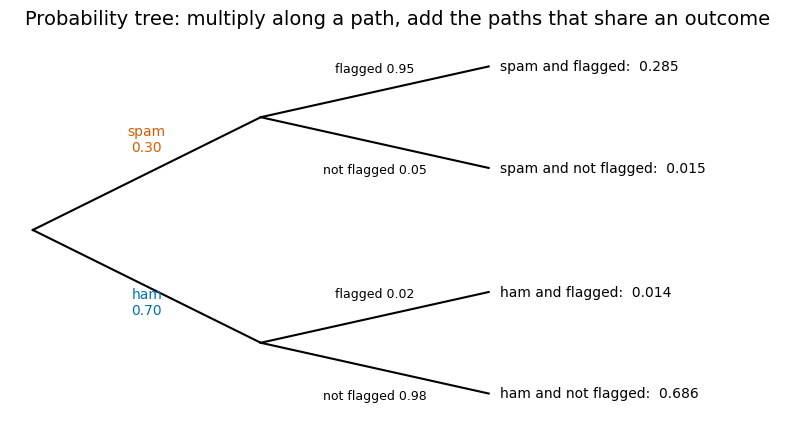

In [2]:
p_spam, sens, fpr = 0.30, 0.95, 0.02
paths = [("spam", "flagged", p_spam * sens), ("spam", "not flagged", p_spam * (1 - sens)), ("ham", "flagged", (1 - p_spam) * fpr), ("ham", "not flagged", (1 - p_spam) * (1 - fpr))]
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot([0, 1], [3, 5], color="black"); ax.plot([0, 1], [3, 1], color="black")
ax.text(0.5, 4.4, f"spam\n{p_spam:.2f}", ha="center", color=HIGHLIGHT); ax.text(0.5, 1.5, f"ham\n{1 - p_spam:.2f}", ha="center", color=MAIN)
for (y0, a, b, c, d) in [(5, "flagged", sens, "not flagged", 1 - sens), (1, "flagged", fpr, "not flagged", 1 - fpr)]:
    ax.plot([1, 2], [y0, y0 + 0.9], color="black"); ax.plot([1, 2], [y0, y0 - 0.9], color="black")
    ax.text(1.5, y0 + 0.8, f"{a} {b:.2f}", ha="center", fontsize=9); ax.text(1.5, y0 - 1.0, f"{c} {d:.2f}", ha="center", fontsize=9)
for (cls, obs, p), y in zip(paths, [5.9, 4.1, 1.9, 0.1]):
    ax.text(2.05, y, f"{cls} and {obs}:  {p:.3f}", va="center", fontsize=10)
ax.set_xlim(-0.1, 3.3); ax.set_ylim(-0.6, 6.5); ax.axis("off"); ax.set_title("Probability tree: multiply along a path, add the paths that share an outcome")
plt.show()
assert np.isclose(sum(p for _, _, p in paths), 1.0)

### 7.2 Natural frequencies: 1,000 emails
The same numbers as counts. Of the 299 flagged emails, 285 are spam and 14 are ham: a flagged email is spam with probability $285/299=95.3\,\%$.

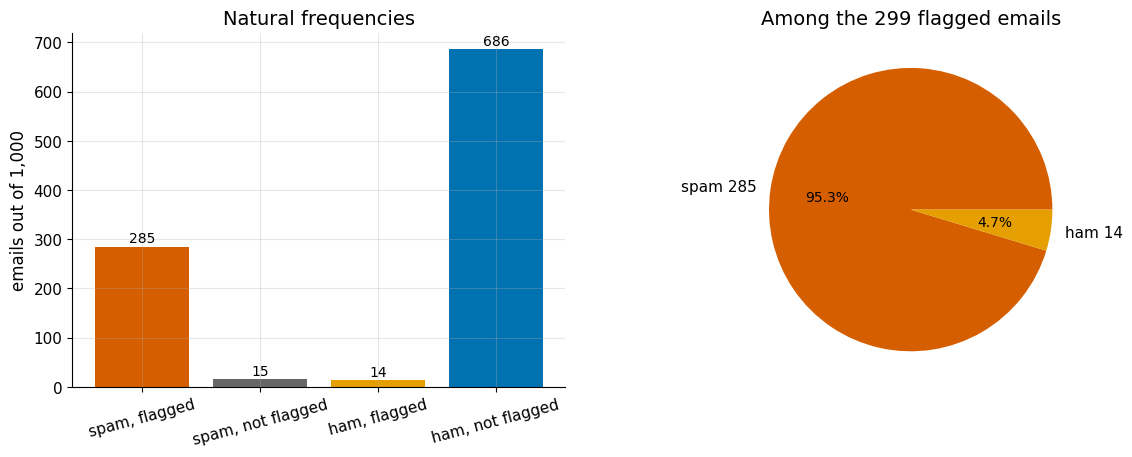

In [3]:
n_emails = 1000
counts = {"spam, flagged": n_emails * p_spam * sens, "spam, not flagged": n_emails * p_spam * (1 - sens), "ham, flagged": n_emails * (1 - p_spam) * fpr, "ham, not flagged": n_emails * (1 - p_spam) * (1 - fpr)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].bar(counts.keys(), counts.values(), color=[HIGHLIGHT, NEUTRAL, SIM, MAIN]); axes[0].set_ylabel("emails out of 1,000"); axes[0].set_title("Natural frequencies"); axes[0].tick_params(axis="x", labelrotation=15)
for i_, v_ in enumerate(counts.values()): axes[0].text(i_, v_ + 8, f"{v_:.0f}", ha="center")
flagged = [counts["spam, flagged"], counts["ham, flagged"]]
axes[1].pie(flagged, labels=[f"spam {flagged[0]:.0f}", f"ham {flagged[1]:.0f}"], colors=[HIGHLIGHT, SIM], autopct="%1.1f%%"); axes[1].set_title("Among the 299 flagged emails")
plt.show()

### 7.3 The base-rate effect
Precision $P(\text{spam}\mid\text{flagged})$ as the share of spam changes, for the same filter (sensitivity 95 %, false positive rate 2 %). When spam is rare, most flagged emails are false alarms.

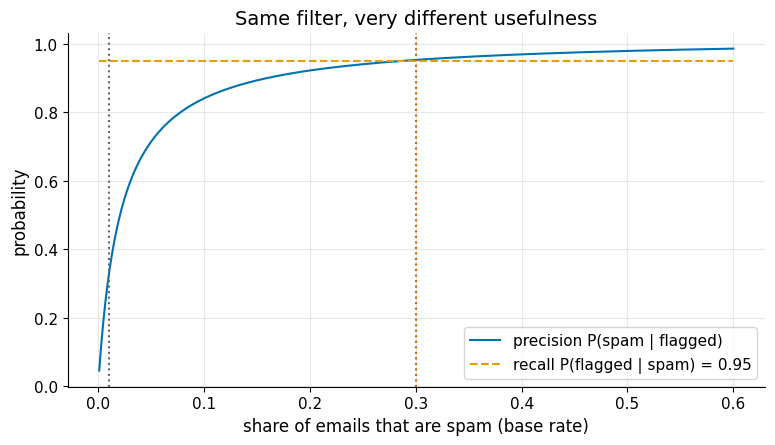

{0.01: 0.3242, 0.05: 0.7143, 0.3: 0.9532, 0.5: 0.9794}


In [4]:
def precision(prev, s=0.95, f=0.02):
    return s * prev / (s * prev + f * (1 - prev))
prev_axis = np.linspace(0.001, 0.6, 300)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(prev_axis, precision(prev_axis), color=MAIN, label="precision P(spam | flagged)")
ax.plot(prev_axis, np.full_like(prev_axis, 0.95), color=SIM, linestyle="--", label="recall P(flagged | spam) = 0.95")
ax.axvline(0.30, color=HIGHLIGHT, linestyle=":"); ax.axvline(0.01, color=NEUTRAL, linestyle=":")
ax.set_xlabel("share of emails that are spam (base rate)"); ax.set_ylabel("probability"); ax.set_title("Same filter, very different usefulness"); ax.legend()
plt.show()
print({pr: round(precision(pr), 4) for pr in (0.01, 0.05, 0.30, 0.50)})
assert np.isclose(precision(0.30), 285 / 299)

### 7.4 Posterior odds = prior odds x likelihood ratio
Each positive result multiplies the odds by $s/f=47.5$. Three independent flags are enough to make even a 1 % base rate nearly certain.

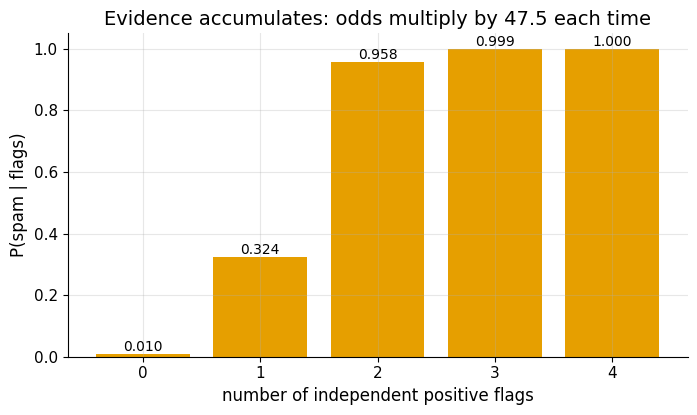

In [5]:
prior = 0.01; lr = 0.95 / 0.02
k_flags = np.arange(0, 5)
odds = prior / (1 - prior) * lr ** k_flags
post = odds / (1 + odds)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(k_flags, post, color=SIM); ax.set_xlabel("number of independent positive flags"); ax.set_ylabel("P(spam | flags)"); ax.set_title("Evidence accumulates: odds multiply by 47.5 each time")
for k_, v_ in zip(k_flags, post): ax.text(k_, v_ + 0.01, f"{v_:.3f}", ha="center")
plt.show()
assert abs(post[1] - 0.3243) < 5e-4

## 8. 3D visuals

### 8.1 Static: precision over (base rate, false positive rate)
With sensitivity fixed at 95 %. The surface falls steeply when the base rate is low and the false positive rate is not tiny: a high-precision detector needs a low false positive rate *relative to the base rate*.

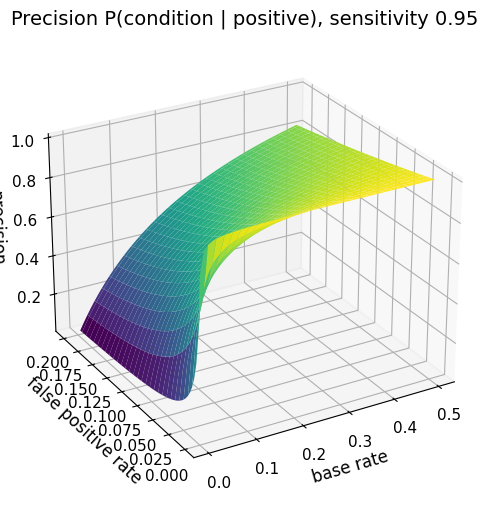

In [6]:
prev_g = np.linspace(0.005, 0.5, 60); fpr_g = np.linspace(0.001, 0.2, 60)
Pg, Fg = np.meshgrid(prev_g, fpr_g)
Z = 0.95 * Pg / (0.95 * Pg + Fg * (1 - Pg))
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Pg, Fg, Z, cmap="viridis", edgecolor="none")
ax.set_title("Precision P(condition | positive), sensitivity 0.95"); ax.set_xlabel("base rate"); ax.set_ylabel("false positive rate"); ax.set_zlabel("precision"); ax.view_init(elev=26, azim=-120)
plt.show()

### 8.2 Interactive Plotly version of 8.1
Hover to read the precision for any base rate and false positive rate.

In [7]:
fig = go.Figure(go.Surface(x=prev_g, y=fpr_g, z=Z, colorscale="Viridis"))
fig.update_layout(title="Precision with sensitivity 0.95", width=750, height=550, scene=dict(xaxis_title="base rate", yaxis_title="false positive rate", zaxis_title="precision"))
fig.show()

## 9. Simulation vs theory

### 9.1 Simulate the emails
Generate 1,000,000 emails with the stated probabilities. Then compute the conditional frequencies from the simulated data and compare with the tree.

In [8]:
n_sim = 1_000_000
is_spam = rng.random(n_sim) < p_spam
flag = np.where(is_spam, rng.random(n_sim) < sens, rng.random(n_sim) < fpr)
print(f"P(flagged) simulated {flag.mean():.4f} | exact {p_spam * sens + (1 - p_spam) * fpr:.4f}")
print(f"P(spam | flagged) simulated {is_spam[flag].mean():.4f} | exact {285 / 299:.4f}")
print(f"P(spam | not flagged) simulated {is_spam[~flag].mean():.4f} | exact {15 / 701:.4f}")
assert abs(is_spam[flag].mean() - 285 / 299) < 0.002 and abs(is_spam[~flag].mean() - 15 / 701) < 0.001

P(flagged) simulated 0.2989 | exact 0.2990
P(spam | flagged) simulated 0.9530 | exact 0.9532
P(spam | not flagged) simulated 0.0214 | exact 0.0214


### 9.2 Rare spam: the same filter on a mailbox with 1 % spam
Only the base rate changes; the filter is identical.

In [9]:
is_spam2 = rng.random(n_sim) < 0.01
flag2 = np.where(is_spam2, rng.random(n_sim) < sens, rng.random(n_sim) < fpr)
print(f"flagged emails that are really spam: simulated {is_spam2[flag2].mean():.4f} | exact {precision(0.01):.4f}")
assert abs(is_spam2[flag2].mean() - precision(0.01)) < 0.01

flagged emails that are really spam: simulated 0.3301 | exact 0.3242


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [10]:
def bayes(prior, likelihood_if_true, likelihood_if_false):
    "Posterior probability of the condition given a positive result."
    evidence = likelihood_if_true * prior + likelihood_if_false * (1 - prior)
    return likelihood_if_true * prior / evidence
print("Bayes for the spam filter:", round(bayes(0.30, 0.95, 0.02), 4), "| prior odds x LR:", round(0.3 / 0.7 * 0.95 / 0.02 / (1 + 0.3 / 0.7 * 0.95 / 0.02), 4))
print("partition and total probability: np.dot(P_B_given_A, P_A) ->", np.dot([0.01, 0.02, 0.03], [0.5, 0.3, 0.2]))
print("simulate a two-stage tree: stage 1 rng.random(n) < p1; stage 2 np.where(stage1, rng.random(n) < p_if_yes, rng.random(n) < p_if_no)")
print("select the condition, then average: flag[is_spam].mean() = recall, is_spam[flag].mean() = precision")
print("number of true alarms in 1,000 flagged emails (Binomial): stats.binom(1000, 285 / 299).mean() ->", round(stats.binom(1000, 285 / 299).mean(), 1))
print("confusion table: pd.crosstab(is_spam, flag) ->"); print(pd.crosstab(is_spam, flag).to_string())

Bayes for the spam filter: 0.9532 | prior odds x LR: 0.9532
partition and total probability: np.dot(P_B_given_A, P_A) -> 0.017
simulate a two-stage tree: stage 1 rng.random(n) < p1; stage 2 np.where(stage1, rng.random(n) < p_if_yes, rng.random(n) < p_if_no)
select the condition, then average: flag[is_spam].mean() = recall, is_spam[flag].mean() = precision
number of true alarms in 1,000 flagged emails (Binomial): stats.binom(1000, 285 / 299).mean() -> 953.2
confusion table: pd.crosstab(is_spam, flag) ->


col_0   False   True 
row_0                
False  686108   14037
True    15035  284820


## 11. Real-world worked examples

---
### Example 1 (main): a spam filter

**Scenario.** 30 % of the incoming emails of a company are spam. A filter **flags 95 % of spam** and also **flags 2 % of legitimate email ("ham")**. Emails are independent.

**Questions**
1. What fraction of all emails does the filter flag?
2. An email is flagged. What is the probability that it is **spam**?
3. An email is **not** flagged. What is the probability that it is spam anyway?
4. Out of **1,000 emails**, how many legitimate emails end up flagged? What happens if only **1 %** of the emails are spam?

### 11.1 By hand
**Tree.** spam & flagged $=0.30\times0.95=0.285$; spam & not flagged $=0.30\times0.05=0.015$; ham & flagged $=0.70\times0.02=0.014$; ham & not flagged $=0.70\times0.98=0.686$.

**Q1.** Total probability: $P(\text{flagged})=0.285+0.014=\mathbf{0.299}$.

**Q2.** Bayes: $P(\text{spam}\mid\text{flagged})=\dfrac{0.285}{0.299}=\mathbf{0.953}$.

**Q3.** $P(\text{spam}\mid\text{not flagged})=\dfrac{0.015}{0.015+0.686}=\dfrac{0.015}{0.701}=\mathbf{0.0214}$.

**Q4.** In 1,000 emails: $700\times0.02=\mathbf{14}$ legitimate emails are flagged (and 285 spam). With 1 % spam: spam & flagged $=0.01\times0.95=0.0095$; ham & flagged $=0.99\times0.02=0.0198$; so $P(\text{spam}\mid\text{flagged})=0.0095/0.0293=\mathbf{0.324}$: two thirds of the flagged emails are legitimate.

In [11]:
p_flag = p_spam * sens + (1 - p_spam) * fpr
post_flag = p_spam * sens / p_flag
post_not = p_spam * (1 - sens) / (1 - p_flag)
print(f"Q1: P(flagged) = {p_flag:.4f}")
print(f"Q2: P(spam | flagged) = {post_flag:.4f}")
print(f"Q3: P(spam | not flagged) = {post_not:.4f}")
print(f"Q4: of 1000 emails, {1000 * (1 - p_spam) * fpr:.0f} legitimate ones are flagged; with 1 % spam: P(spam | flagged) = {precision(0.01):.4f} -> {1 - precision(0.01):.1%} of flagged emails are legitimate")

Q1: P(flagged) = 0.2990
Q2: P(spam | flagged) = 0.9532
Q3: P(spam | not flagged) = 0.0214
Q4: of 1000 emails, 14 legitimate ones are flagged; with 1 % spam: P(spam | flagged) = 0.3242 -> 67.6% of flagged emails are legitimate


### 11.2 In code with `scipy`, and the asserts

In [12]:
assert np.isclose(p_flag, 0.299) and np.isclose(post_flag, 285 / 299) and np.isclose(post_not, 15 / 701)
assert np.isclose(bayes(0.30, 0.95, 0.02), post_flag) and abs(precision(0.01) - 0.3243) < 5e-4
assert np.isclose(sum(p for _, _, p in paths), 1) and np.isclose(post_flag * p_flag + post_not * (1 - p_flag), p_spam)     # total probability of spam is recovered
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
The 1,000,000 simulated emails of Section 9 already agree; here is the 2 x 2 confusion table as proportions, and the four numbers the tree predicted.

In [13]:
conf = pd.crosstab(is_spam, flag, normalize="all")
conf.index = ["ham", "spam"]; conf.columns = ["not flagged", "flagged"]
print(conf.round(4).to_string())
print("tree:", {f"{c} and {o}": round(p, 3) for c, o, p in paths})
assert np.allclose(conf.loc["spam", "flagged"], 0.285, atol=0.002) and np.allclose(conf.loc["ham", "flagged"], 0.014, atol=0.001)

      not flagged  flagged
ham        0.6861   0.0140
spam       0.0150   0.2848
tree: {'spam and flagged': 0.285, 'spam and not flagged': 0.015, 'ham and flagged': 0.014, 'ham and not flagged': 0.686}


### 11.4 Plots with the regions shaded

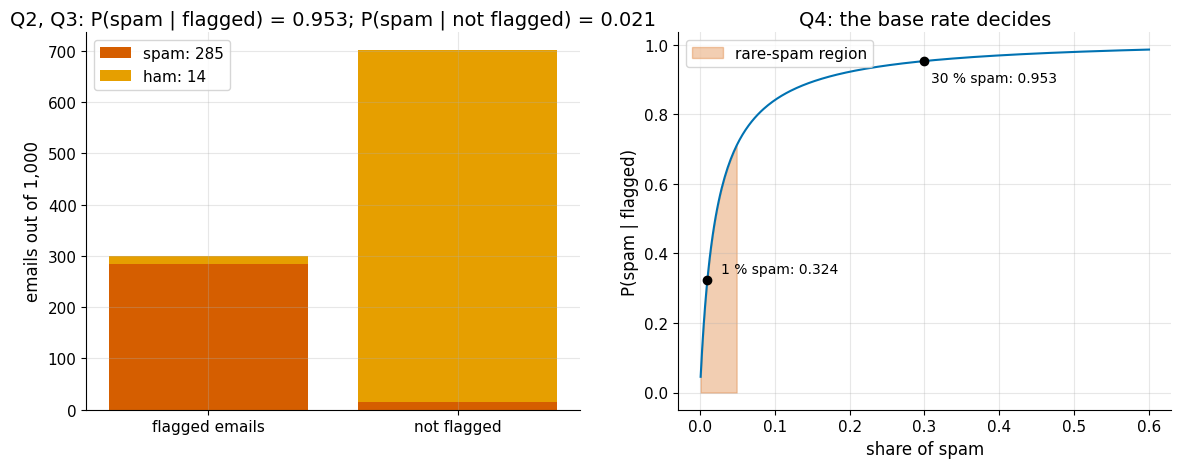

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
sizes = [285, 14]; axes[0].bar(["flagged emails"], [285], color=HIGHLIGHT, label="spam: 285"); axes[0].bar(["flagged emails"], [14], bottom=[285], color=SIM, label="ham: 14")
axes[0].bar(["not flagged"], [15], color=HIGHLIGHT); axes[0].bar(["not flagged"], [686], bottom=[15], color=SIM)
axes[0].set_ylabel("emails out of 1,000"); axes[0].set_title(f"Q2, Q3: P(spam | flagged) = {post_flag:.3f}; P(spam | not flagged) = {post_not:.3f}"); axes[0].legend()
axes[1].plot(prev_axis, precision(prev_axis), color=MAIN); axes[1].fill_between(prev_axis, 0, precision(prev_axis), where=prev_axis < 0.05, color=HIGHLIGHT, alpha=0.3, label="rare-spam region")
axes[1].scatter([0.30, 0.01], [precision(0.30), precision(0.01)], color="black", zorder=3); axes[1].annotate("30 % spam: 0.953", (0.30, precision(0.30)), textcoords="offset points", xytext=(5, -15)); axes[1].annotate("1 % spam: 0.324", (0.01, precision(0.01)), textcoords="offset points", xytext=(10, 5))
axes[1].set_xlabel("share of spam"); axes[1].set_ylabel("P(spam | flagged)"); axes[1].set_title("Q4: the base rate decides"); axes[1].legend()
plt.show()

### 11.5 Interpretation and decision (Example 1)
- The filter flags **29.9 %** of all emails. A flagged email is spam with probability **95.3 %** (285 of the 299 flagged emails in a group of 1,000), and an unflagged email is still spam with probability only **2.1 %** (15 of 701). Simulation of 1,000,000 emails gives 0.9530 and 0.0214.
- **The same filter on a different mailbox.** If only **1 %** of the emails are spam, a flagged email is spam with probability **32.4 %**: two out of three flagged emails (67.6 %) are legitimate, although the filter itself did not change. The base rate decides how trustworthy a flag is.
- **Decision.** For a mailbox with 30 % spam it is safe to move flagged emails automatically to the spam folder (96 % right), but for a mailbox with 1 % spam move them only to a "review" folder or tighten the filter, because a third of the deleted mail would be legitimate.

---
### Example 2: three machines in a factory (total probability and "which machine?")

**Scenario.** Machine A makes **50 %** of the parts with **1 %** defective; machine B makes **30 %** with **2 %** defective; machine C makes **20 %** with **3 %** defective. What is the overall defect rate? A part is found defective: which machine most likely made it?

### 11.6 By hand, in code and by simulation
**By hand.** $P(\text{def})=0.5\cdot0.01+0.3\cdot0.02+0.2\cdot0.03=0.005+0.006+0.006=\mathbf{0.017}$. Posteriors: $P(A\mid\text{def})=0.005/0.017=0.294$, $P(B\mid\text{def})=0.006/0.017=0.353$, $P(C\mid\text{def})=0.006/0.017=0.353$.

P(defective) = 0.0170 | P(machine | defective) = {'A': np.float64(0.2941), 'B': np.float64(0.3529), 'C': np.float64(0.3529)} | sums to 1.00
simulated: P(defective) = 0.0169 | posterior [0.2929 0.3541 0.3531]


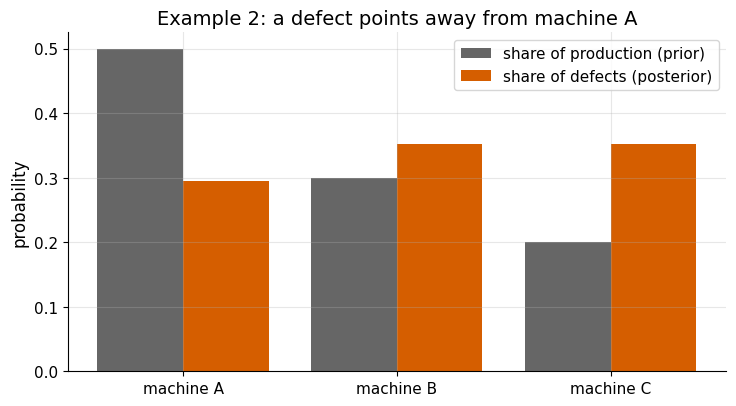

In [15]:
share = np.array([0.5, 0.3, 0.2]); defect = np.array([0.01, 0.02, 0.03])
p_def = np.dot(defect, share); posterior = defect * share / p_def
print(f"P(defective) = {p_def:.4f} | P(machine | defective) = {dict(zip('ABC', posterior.round(4)))} | sums to {posterior.sum():.2f}")
machine = np.random.default_rng(5).choice(3, 2_000_000, p=share); is_def = np.random.default_rng(6).random(2_000_000) < defect[machine]
sim_post = np.bincount(machine[is_def], minlength=3) / is_def.sum()
print(f"simulated: P(defective) = {is_def.mean():.4f} | posterior {sim_post.round(4)}")
assert np.isclose(p_def, 0.017) and np.allclose(posterior, [5 / 17, 6 / 17, 6 / 17]) and np.allclose(sim_post, posterior, atol=0.004)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
xx = np.arange(3); ax.bar(xx - 0.2, share, 0.4, color=NEUTRAL, label="share of production (prior)"); ax.bar(xx + 0.2, posterior, 0.4, color=HIGHLIGHT, label="share of defects (posterior)")
ax.set_xticks(xx); ax.set_xticklabels(["machine A", "machine B", "machine C"]); ax.set_ylabel("probability"); ax.set_title("Example 2: a defect points away from machine A"); ax.legend()
plt.show()

### 11.6b Interpretation and decision (Example 2)
- The overall defect rate is **1.7 %**. Machine A makes half of the parts but only **29.4 %** of the defects; machines B and C each produce **35.3 %** of the defects (C with only 20 % of production). The simulation gives 29.3 %, 35.4 % and 35.3 %.
- A defective part is therefore **not** most likely to come from the biggest producer: the posterior weights each machine's output by its defect rate.
- **Decision.** Inspect machines B and C first when defects appear; reducing C's defect rate from 3 % to 2 % would lower the overall rate from 1.7 % to 1.5 %.

---
### Example 3: fraud alerts when fraud is very rare

**Scenario.** **0.2 %** of card transactions are fraudulent. A detector raises an alert for **98 %** of fraudulent transactions and falsely for **3 %** of legitimate ones. A transaction triggers an alert. What is the probability that it is fraud? How many false alerts does a bank see per true alert?

### 11.7 By hand, in code and by simulation
**By hand.** Fraud & alert $=0.002\times0.98=0.00196$; legitimate & alert $=0.998\times0.03=0.02994$; $P(\text{fraud}\mid\text{alert})=\dfrac{0.00196}{0.00196+0.02994}=\mathbf{0.0614}$. So about 15 false alerts per true alert ($0.02994/0.00196=15.3$). In 100,000 transactions: 196 true alerts and 2,994 false ones.

P(fraud | alert) = 0.0614 | false alerts per true alert = 15.3 | per 100,000 transactions: 196 true alerts, 2994 false alerts
simulated P(fraud | alert) = 0.0616 | alerts 0.0320 (exact 0.0319)
precision if the false alert rate were [0.03, 0.01, 0.003, 0.001] -> [0.061, 0.164, 0.396, 0.663]


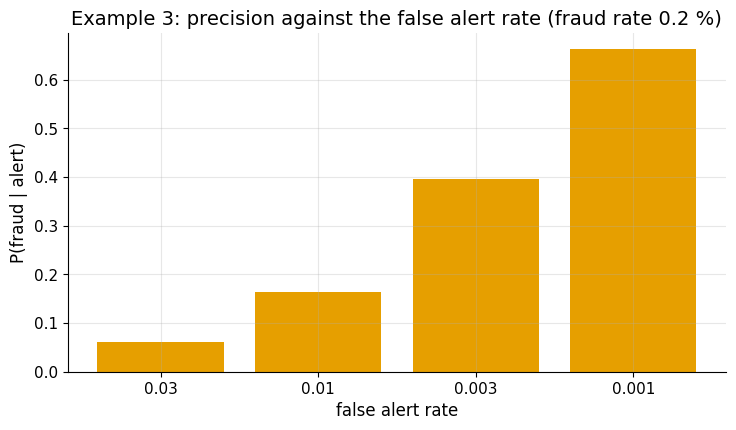

In [16]:
pi_f, s_f, f_f = 0.002, 0.98, 0.03
post_f = bayes(pi_f, s_f, f_f)
print(f"P(fraud | alert) = {post_f:.4f} | false alerts per true alert = {(1 - pi_f) * f_f / (pi_f * s_f):.1f} | per 100,000 transactions: {pi_f * s_f * 100_000:.0f} true alerts, {(1 - pi_f) * f_f * 100_000:.0f} false alerts")
fr = np.random.default_rng(7).random(3_000_000) < pi_f
al = np.where(fr, np.random.default_rng(8).random(3_000_000) < s_f, np.random.default_rng(9).random(3_000_000) < f_f)
print(f"simulated P(fraud | alert) = {fr[al].mean():.4f} | alerts {al.mean():.4f} (exact {pi_f * s_f + (1 - pi_f) * f_f:.4f})")
assert abs(post_f - 0.0614) < 5e-4 and abs(fr[al].mean() - post_f) < 0.006
better_f = [0.03, 0.01, 0.003, 0.001]
print("precision if the false alert rate were", better_f, "->", [round(bayes(pi_f, s_f, f_), 3) for f_ in better_f])
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.bar([str(f_) for f_ in better_f], [bayes(pi_f, s_f, f_) for f_ in better_f], color=SIM); ax.set_xlabel("false alert rate"); ax.set_ylabel("P(fraud | alert)"); ax.set_title("Example 3: precision against the false alert rate (fraud rate 0.2 %)")
plt.show()

### 11.7b Interpretation and decision (Example 3)
- With 0.2 % fraud, a detector that catches 98 % of fraud and wrongly alerts on 3 % of legitimate transactions is right on only **6.1 %** of its alerts (the simulation gives 6.2 %). Among 100,000 transactions there are **196 true alerts and 2,994 false ones**: about **15 false alerts for each true one**.
- Cutting the false alert rate from 3 % to 1 % raises the precision only to 16.4 %; **0.3 %** gives 39.6 % and **0.1 %** gives 66.3 %.
- **Decision.** Accuracy and recall alone are misleading for rare events; judge a fraud detector by its precision at the real fraud rate, and add a second, cheap check (an SMS confirmation) before blocking cards, so that false alerts do not overwhelm the analysts.

## 12. Where it is used

### Statistics
- **Bayes' theorem is the engine of Bayesian inference** (Module 07): prior $\times$ likelihood $\propto$ posterior; **total probability** gives the normalising constant (the evidence).
- **Screening, diagnostic testing and hypothesis testing** are two-stage trees; the false discovery rate is $1-$ precision.

### Data science
- **Fraud, churn, anomaly and spam detection** work on rare classes, so precision is dominated by the base rate (Examples 1 and 3); **alert fatigue** is a precision problem.
- **Root-cause analysis** ("which machine / server / release produced this defect?", Example 2) is Bayes' theorem over a partition.

### ML and AI
- **Classification metrics are conditional probabilities:** recall $=P(+\mid\text{positive})$ and precision $=P(\text{positive}\mid+)$ and they depend on the class balance; **naive Bayes** classifiers apply Bayes' theorem with conditionally independent features.
- **Probabilistic models and posteriors:** language-model decoding, **calibration** (does a predicted 90 % come true 90 % of the time?), **spam filtering** and **Bayesian updating** in online learning (posterior odds = prior odds $\times$ likelihood ratio).

## 13. Common pitfalls and misconceptions

- **Base-rate neglect:** ignoring how rare the condition is. A "95 % accurate" detector for a 0.2 % problem is wrong about 94 % of its alerts (Example 3).
- **Confusing sensitivity with precision:** $P(+\mid D)\ne P(D\mid+)$ (0a_04, 5.5).
- **Forgetting the false-alarm path:** the denominator must include *all* ways to get the observation (the tree's other branches).
- **Probabilities that do not add up:** the branches leaving one node must sum to 1; the final path probabilities must sum to 1.
- **Percentages versus counts:** natural frequencies ("14 out of 1,000") are less error-prone than percentages.
- **Treating repeated alerts as independent** when they come from the same cause (a repeat of the same email, a repeat of the same customer) multiplies the likelihood ratio wrongly.
- **Using the prior from the wrong population:** the base rate must be the rate in the population being tested, not in the lab.

## 14. Exercises

1. A bag holds 3 fair coins and 1 two-headed coin. One coin is chosen at random and tossed: it shows heads. What is the probability that it is the two-headed coin?
2. A student guesses on 30 % of the questions (and is right 25 % of the time when guessing); on the other 70 % the student knows the answer and is right 95 % of the time. A question is answered correctly. What is the probability the student was guessing?
3. 1 % of a population has a disease. A test has sensitivity 90 % and specificity 95 %. Compute $P(\text{disease}\mid+)$ and $P(\text{disease}\mid-)$, and express them as natural frequencies for 10,000 people.
4. Two independent positive tests for the disease of Exercise 3 are obtained (both positive). Using posterior odds, find the probability of disease.
5. A factory has three shifts producing 40 %, 35 % and 25 % of the output with defect rates 2 %, 3 % and 5 %. A defective item is found. Which shift is most probably responsible?
6. (Harder) A detector with sensitivity 90 % is used where the condition has prevalence 0.5 %. What false positive rate is needed to make its precision at least 50 %?

Solutions are at the end.

## 15. Summary table

| Task | Formula | Tool |
|---|---|---|
| Overall chance of the observation | $P(B)=\sum P(B\mid A_i)P(A_i)$ | tree: add the paths |
| Reverse a conditional | $P(A_j\mid B)=\dfrac{P(B\mid A_j)P(A_j)}{P(B)}$ | tree: path share |
| Detector precision | $\dfrac{s\pi}{s\pi+f(1-\pi)}$ | natural frequencies |
| Odds form | posterior odds $=$ prior odds $\times\ s/f$ | repeated evidence |
| Sensitivity (recall) | $P(+\mid D)$ | confusion matrix row |
| Precision | $P(D\mid+)$ | confusion matrix column |
| Partition check | $\sum P(A_i)=1$ | before using total probability |

## Solutions

In [17]:
print(f"1: P(two-headed | heads) = {1 / 4 * 1 / (1 / 4 * 1 + 3 / 4 * 0.5):.4f}")
guess = 0.3 * 0.25; know = 0.7 * 0.95
print(f"2: P(guessing | correct) = {guess / (guess + know):.4f}")
tp, fn = 0.01 * 0.90, 0.01 * 0.10; fp, tn = 0.99 * 0.05, 0.99 * 0.95
print(f"3: P(disease | +) = {tp / (tp + fp):.4f} | P(disease | -) = {fn / (fn + tn):.5f} | per 10,000: {10000 * tp:.0f} true positives, {10000 * fp:.0f} false positives, {10000 * fn:.0f} missed cases")
odds2 = 0.01 / 0.99 * (0.90 / 0.05) ** 2
print(f"4: posterior odds {odds2:.3f} -> probability {odds2 / (1 + odds2):.4f}")
shift = np.array([0.40, 0.35, 0.25]) * np.array([0.02, 0.03, 0.05]); print("5: P(shift | defect) =", (shift / shift.sum()).round(4), "-> shift 3 is most likely despite making the least")
f_need = 0.9 * 0.005 / 0.5 - 0.9 * 0.005     # s pi = f (1 - pi) when precision = 0.5  ->  f = s pi / (1 - pi)
print(f"6: need f <= {0.9 * 0.005 / (1 - 0.005):.5f}  (precision at that rate: {bayes(0.005, 0.9, 0.9 * 0.005 / 0.995):.3f})")

1: P(two-headed | heads) = 0.4000
2: P(guessing | correct) = 0.1014
3: P(disease | +) = 0.1538 | P(disease | -) = 0.00106 | per 10,000: 90 true positives, 495 false positives, 10 missed cases
4: posterior odds 3.273 -> probability 0.7660
5: P(shift | defect) = [0.2581 0.3387 0.4032] -> shift 3 is most likely despite making the least
6: need f <= 0.00452  (precision at that rate: 0.500)


**1.** Heads from the fair coin: $\tfrac34\times\tfrac12=0.375$; from the two-headed coin: $\tfrac14\times1=0.25$. $P(\text{two-headed}\mid\text{heads})=\dfrac{0.25}{0.625}=\mathbf{0.40}$.

**2.** Guessing and correct: $0.3\times0.25=0.075$; knowing and correct: $0.7\times0.95=0.665$. $P(\text{guessing}\mid\text{correct})=\dfrac{0.075}{0.74}=\mathbf{0.101}$.

**3.** True positives $0.01\times0.90=0.009$; false positives $0.99\times0.05=0.0495$. $P(\text{disease}\mid+)=0.009/0.0585=\mathbf{0.154}$. Missed cases $0.01\times0.10=0.001$; true negatives $0.99\times0.95=0.9405$; $P(\text{disease}\mid-)=0.001/0.9415=\mathbf{0.00106}$. Per 10,000 people: **90** true positives, **495** false positives and **10** missed cases.

**4.** Prior odds $0.01/0.99=0.0101$; likelihood ratio per positive test $0.90/0.05=18$, so after two tests the odds are $0.0101\times18^2=3.27$ and the probability is $3.27/4.27=\mathbf{0.766}$. A second independent positive test raises the chance from 15 % to 77 %.

**5.** Joint weights $0.40\times0.02=0.008$, $0.35\times0.03=0.0105$, $0.25\times0.05=0.0125$; the total is 0.031. Posteriors: **25.8 %, 33.9 %, 40.3 %**. Shift 3 is the most probable source although it makes the least output.

**6.** Precision 0.5 means $s\pi=f(1-\pi)$, so $f=\dfrac{s\pi}{1-\pi}=\dfrac{0.9\times0.005}{0.995}=\mathbf{0.00452}$: the false positive rate must be below **0.45 %** (specificity at least 99.55 %), nearly ten times better than the rate that suffices for a common condition.